In [1]:
import sys
sys.path.append("../src")
from openf1_client import get

In [2]:
laps = get("laps", session_key = 11228)
stints = get("stints", session_key = 11228)

merged = laps.merge(stints[["driver_number", "stint_number", "lap_start", "lap_end",
                       "compound", "tyre_age_at_start"]], on="driver_number")

print(len(laps), len(merged))

544 2304


In [3]:
laps_st = merged[(merged["lap_number"] >= merged["lap_start"]) & (merged["lap_number"] <= merged["lap_end"])]
len(laps_st)

544

In [4]:
laps_st = laps_st.copy()
laps_st["tyre_age"] = laps_st["tyre_age_at_start"] + (laps_st["lap_number"] - laps_st["lap_start"])


In [5]:
laps_st = laps_st.copy()
laps_st["is_pit_in_lap"] = laps_st["lap_number"] == laps_st["lap_end"]
print(laps_st["is_pit_in_lap"].sum())

86


In [14]:
not_out  = ~laps_st["is_pit_out_lap"]
not_in   = ~laps_st["is_pit_in_lap"]
has_time = laps_st["lap_duration"].notna()
not_neutralised = ~laps_st["is_neutralised"]
not_deleted = ~laps_st["is_deleted"]

keep = not_out & not_in & has_time &not_neutralised & not_deleted
clean = laps_st[keep].copy()
print(len(clean))

336


In [7]:
from track_status import add_track_status_flags


rc = get("race_control", session_key = 11228)
laps_st = add_track_status_flags(laps_st,rc)
print(laps_st["is_neutralised"].sum(), laps_st["is_deleted"].sum())

49 13


In [9]:
clean["stint_best"] = clean.groupby(["driver_number", "stint_number"])["lap_duration"].transform("min")

within107 = clean["lap_duration"] < (1.07 * clean["stint_best"])
clean = clean[within107].copy()
print(len(clean))

229


In [2]:
from lap_table import build_lap_table
for key in [11406, 11228, 11414]:
    t = build_lap_table(key)
    print(key, len(t))

11406 359
11228 229
11414 153


<Axes: title={'center': 'Melbourne FP2 - Leclerc (clean laps)'}, xlabel='Lap number', ylabel='Lap time (s)'>

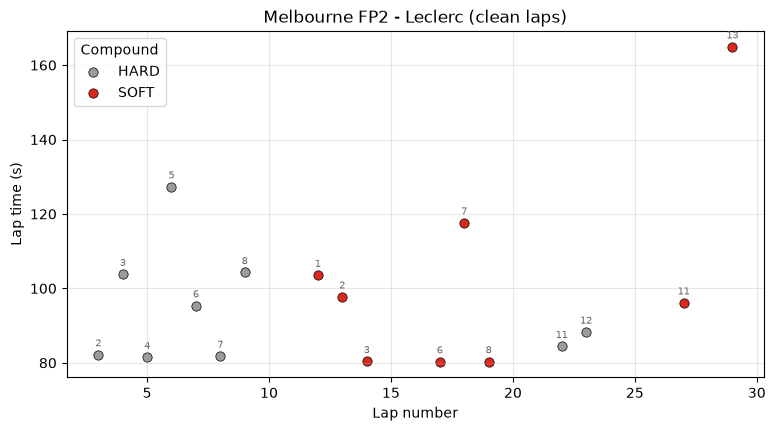

In [15]:
from plots import plot_driver_laps

plot_driver_laps(clean, 16, "Melbourne FP2 - Leclerc (clean laps)")

**Conclusion:** I have correlated each lap with each stint per driver. The graphic shows a long run between laps 20-30, on soft tyres, with a fast paced aproach on the first three laps with softs. 